DATASET INFORMATION
-------------------
Number of records: 4601
Number of input features: 57

First five records:
   feature_1  feature_2  feature_3  feature_4  feature_5  feature_6  \
0       0.00       0.64       0.64        0.0       0.32       0.00   
1       0.21       0.28       0.50        0.0       0.14       0.28   
2       0.06       0.00       0.71        0.0       1.23       0.19   
3       0.00       0.00       0.00        0.0       0.63       0.00   
4       0.00       0.00       0.00        0.0       0.63       0.00   

   feature_7  feature_8  feature_9  feature_10  ...  feature_48  feature_49  \
0       0.00       0.00       0.00        0.00  ...         0.0        0.00   
1       0.21       0.07       0.00        0.94  ...         0.0        0.00   
2       0.19       0.12       0.64        0.25  ...         0.0        0.01   
3       0.31       0.63       0.31        0.63  ...         0.0        0.00   
4       0.31       0.63       0.31        0.63  ...         0.0 

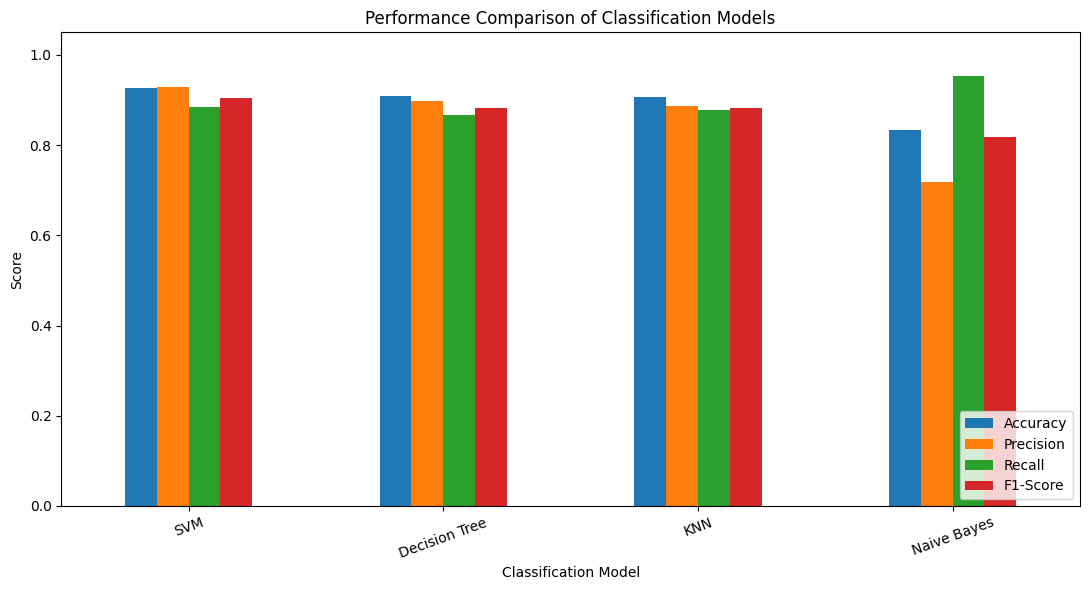

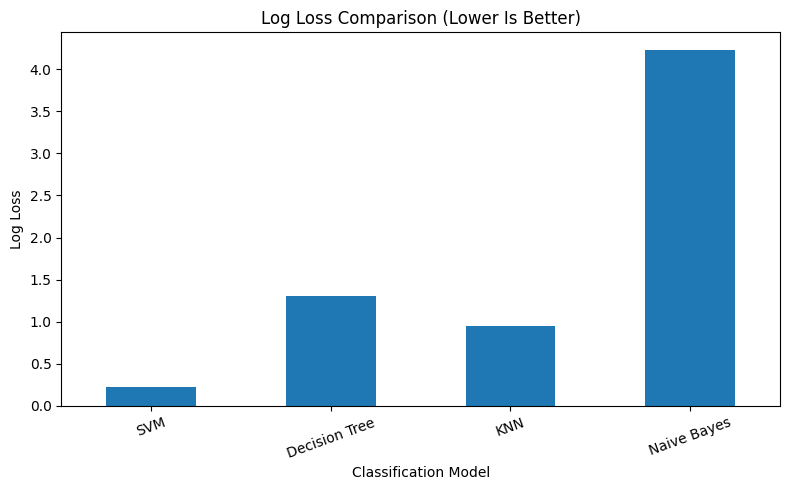

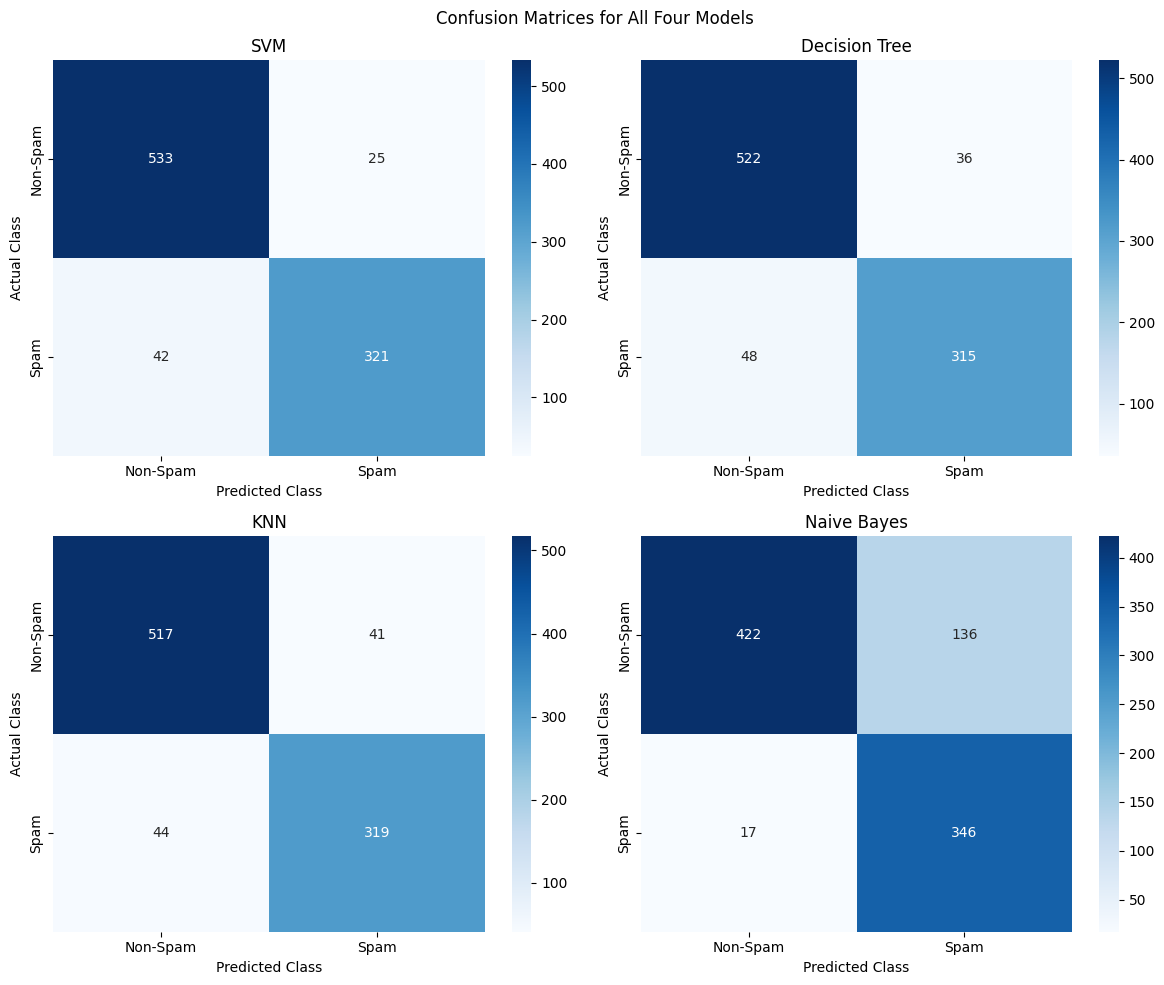


FINAL SUMMARY
-------------
Highest Accuracy: SVM
Highest Precision: SVM
Highest Spam Recall: Naive Bayes
Highest F1-Score: SVM
Lowest Log Loss: SVM

Evaluation completed successfully.


In [ ]:

# Practical Assignment 4
# Comparative Analysis of Classification Models for Email Spam Detection

# 1. Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    confusion_matrix
)

# 2. Load the UCI Spambase dataset
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/spambase/spambase.data"
)

data = pd.read_csv(url, header=None)

# The first 57 columns are features; the last column is the target
X = data.iloc[:, :-1]
y = data.iloc[:, -1].astype(int)

X.columns = [f"feature_{i}" for i in range(1, 58)]

print("DATASET INFORMATION")
print("-------------------")
print("Number of records:", X.shape[0])
print("Number of input features:", X.shape[1])
print("\nFirst five records:")
print(X.head())
print("\nClass distribution:")
print(y.map({0: "Non-Spam", 1: "Spam"}).value_counts())
print("\nMissing values:", data.isnull().sum().sum())

# 3. Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTRAIN-TEST SPLIT")
print("----------------")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# 4. Define the four classification models
models = {
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Naive Bayes": GaussianNB()
}

# 5. Train the models and evaluate their performance
results = []
predictions = {}

for name, model in models.items():

    # Train the model
    model.fit(X_train, y_train)

    # Predict class labels and spam probabilities
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Log Loss": log_loss(y_test, y_prob, labels=[0, 1])
    })

# 6. Display the comparison table
results_df = pd.DataFrame(results).set_index("Model")

print("\nMODEL PERFORMANCE COMPARISON")
print("----------------------------")
print(results_df.round(4))

# 7. Identify the best model for each metric
print("\nBEST MODEL BY METRIC")
print("--------------------")

for metric in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    best = results_df[metric].idxmax()
    print(f"Highest {metric}: {best} "
          f"({results_df.loc[best, metric]:.4f})")

best_loss = results_df["Log Loss"].idxmin()
print(f"Lowest Log Loss: {best_loss} "
      f"({results_df.loc[best_loss, 'Log Loss']:.4f})")

# 8. Compare accuracy, precision, recall and F1-score
results_df[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(kind="bar", figsize=(11, 6), ylim=(0, 1.05))

plt.title("Performance Comparison of Classification Models")
plt.xlabel("Classification Model")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# 9. Compare log loss separately
results_df["Log Loss"].plot(kind="bar", figsize=(8, 5))

plt.title("Log Loss Comparison (Lower Is Better)")
plt.xlabel("Classification Model")
plt.ylabel("Log Loss")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 10. Generate confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, y_pred) in zip(
    axes.flatten(), predictions.items()
):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-Spam", "Spam"],
        yticklabels=["Non-Spam", "Spam"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.suptitle("Confusion Matrices for All Four Models")
plt.tight_layout()
plt.show()

# 11. Final summary
print("\nFINAL SUMMARY")
print("-------------")
print("Highest Accuracy:", results_df["Accuracy"].idxmax())
print("Highest Precision:", results_df["Precision"].idxmax())
print("Highest Spam Recall:", results_df["Recall"].idxmax())
print("Highest F1-Score:", results_df["F1-Score"].idxmax())
print("Lowest Log Loss:", results_df["Log Loss"].idxmin())

print("\nEvaluation completed successfully.")
